# Industry Project: Where the Math Bites in Real Engineering (Production-Style)

> **Who is this notebook for?** Someone who has seen the formulas in this folder and wonders *"where would this ever break my code?"*
> No proofs. Every formula appears next to the few lines of code that implement it, and every section ends with the rule engineers actually follow.

---

### How this notebook is different from `01`-`07` in this folder

| Notebooks `01`-`07` | This notebook |
|---|---|
| Teach the math: linear algebra, calculus, probability, statistics, information theory, optimisation | Shows the **bugs** that appear when that math meets a computer: rounding, overflow, ill-conditioning, slow loops, overconfident numbers, wrong gradients |
| Formulas are exact on paper | Computers use **floating-point numbers**, so `0.1 + 0.2 != 0.3` and `exp(1000)` is infinite |
| `np.linalg.inv` and `solve` shown side by side | *Why* production code never inverts a matrix, measured with condition numbers and errors |
| Finite differences to approximate derivatives | Finite differences as a **unit test** for hand-written gradients (gradient checking), including how to choose the step size |
| Bootstrap on a toy array | Bootstrap **confidence intervals for business numbers**, and a check that they really cover 95% of the time |

---

### The business problem

You are the engineer on an ML platform team. In one quarter, the team saw these incidents:

1. A **revenue dashboard** summed millions of float32 transaction amounts and was off by thousands of dollars.
2. A **sensor-monitoring job** reported a *negative variance* and crashed when taking its square root.
3. A **text classifier** started returning `NaN` probabilities after a model update produced large logits.
4. A **pricing model** fitted with the normal equations gave wildly different coefficients after a tiny data change.
5. A **feature pipeline** written with Python loops took 40 minutes; the vectorised rewrite takes seconds.
6. A **weekly KPI report** said "conversion rose from 3.1% to 3.4%" based on 2,000 visitors: nobody asked how uncertain that was.
7. A **custom loss function** trained "fine" but slowly converged to a worse model: its hand-written gradient had a bug.

Each incident is a piece of the math in this folder showing up in production. We reproduce each one, explain it in plain English, and fix it the way industry code does.

### Table of Contents
1. Setup
2. Floating-point numbers: why `0.1 + 0.2 != 0.3`
3. Summation error: when adding up numbers goes wrong
4. Catastrophic cancellation: the negative variance
5. Stable softmax, log-sum-exp and log-probabilities
6. Why we never invert matrices: `solve`, `lstsq` and condition numbers
7. Vectorisation: loops vs NumPy
8. Sampling and confidence intervals for business numbers
9. Gradient checking a hand-written gradient
10. Automated tests for the numerical helpers
11. The math bug checklist, summary, exercises and resources

---
## 1. Setup

In [1]:
import math                                   # math.fsum = exactly rounded sum (reference answer)
import time                                   # timing benchmarks
import warnings
from decimal import Decimal                   # exact decimal arithmetic for money

import matplotlib.pyplot as plt
import numpy as np
from scipy.special import logsumexp           # library implementation to compare with ours

warnings.filterwarnings("ignore")             # we create overflows ON PURPOSE; keep the output readable
np.set_printoptions(precision=4, suppress=False)
rng = np.random.default_rng(42)               # fixed seed: same numbers every run
COLORS = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "grey": "#8a8984", "red": "#e34948"}
print("NumPy", np.__version__)

NumPy 2.4.6


---
## 2. Floating-point numbers: why `0.1 + 0.2 != 0.3`

A computer stores a real number as a **float**: a sign, a fraction with a fixed number of binary digits, and an exponent (standard **IEEE 754**). Most decimal numbers, like 0.1, have no exact binary representation, the same way 1/3 has no exact decimal one. The stored value is the nearest representable number, so every operation can add a tiny **rounding error**.

The size of that error is set by **machine epsilon** $\varepsilon$: the gap between 1.0 and the next float.

| type | bits | $\varepsilon$ | about how many correct decimal digits |
|---|---|---|---|
| `float16` | 16 | $\approx 10^{-3}$ | 3 |
| `float32` (GPUs, deep learning) | 32 | $\approx 1.2\times10^{-7}$ | 7 |
| `float64` (NumPy default) | 64 | $\approx 2.2\times10^{-16}$ | 16 |

**Rule 1:** never compare floats with `==`; use a tolerance: $|a-b| \le \text{atol} + \text{rtol}\cdot|b|$ (that is exactly what `np.isclose` computes).
**Rule 2:** money is not a float. Use integer cents or `Decimal`.

In [2]:
print("0.1 + 0.2 == 0.3          ->", 0.1 + 0.2 == 0.3)
print("0.1 + 0.2                 ->", repr(0.1 + 0.2))
print("np.isclose(0.1 + 0.2, 0.3)->", np.isclose(0.1 + 0.2, 0.3))           # |a-b| <= atol + rtol*|b|

for dtype in (np.float16, np.float32, np.float64):
    print(f"{np.dtype(dtype).name:8s} eps = {np.finfo(dtype).eps:.3e} | largest = {np.finfo(dtype).max:.3e}")

# Rounding error grows with magnitude: above 2**24 float32 cannot even count by 1
big = np.float32(2**24)
print("\nfloat32: 16_777_216 + 1 =", big + np.float32(1), " (the +1 is lost)")

# Money: 10 payments of $0.10, added one by one
total = 0.0
for _ in range(10):
    total += 0.10
print("\nfloat   total of 10 x 0.10:", repr(total), "| == 1.0?", total == 1.0)
print("(Python 3.12+ built-in sum() is compensated and gives", sum([0.10] * 10), "- but loops and most tools are not)")
print("Decimal total of 10 x 0.10:", sum([Decimal("0.10")] * 10))
print("integer cents             :", sum([10] * 10), "cents")

0.1 + 0.2 == 0.3          -> False
0.1 + 0.2                 -> 0.30000000000000004
np.isclose(0.1 + 0.2, 0.3)-> True
float16  eps = 9.766e-04 | largest = 6.550e+04
float32  eps = 1.192e-07 | largest = 3.403e+38
float64  eps = 2.220e-16 | largest = 1.798e+308

float32: 16_777_216 + 1 = 1.6777216e+07  (the +1 is lost)

float   total of 10 x 0.10: 0.9999999999999999 | == 1.0? False
(Python 3.12+ built-in sum() is compensated and gives 1.0 - but loops and most tools are not)
Decimal total of 10 x 0.10: 1.00
integer cents             : 100 cents


---
## 3. Summation error: when adding up numbers goes wrong

**Incident 1.** The dashboard summed one million transaction amounts stored as `float32` with a simple running total:

$$S_k = S_{k-1} + x_k$$

Each addition rounds to about 7 significant digits. Once the running total is large (millions of dollars), every new small amount is rounded **relative to the big total**, and the errors pile up.

Three better ways, all one-liners:
- `np.sum` uses **pairwise summation** (adds numbers in a balanced tree), so the error grows like $\log n$ instead of $n$.
- **Accumulate in float64** even if the data is stored as float32 (`dtype=np.float64`).
- `math.fsum` returns the correctly rounded sum (slower, good as a reference). **Kahan summation** (below) is the classic trick: it carries the lost low-order bits in a separate variable.

In [3]:
amounts = rng.lognormal(mean=3.0, sigma=1.0, size=1_000_000).round(2).astype(np.float32)  # $ per transaction
exact = math.fsum(amounts.astype(np.float64))          # reference: correctly rounded sum of the stored values

running_float32 = np.cumsum(amounts, dtype=np.float32)[-1]   # S_k = S_{k-1} + x_k, rounded to float32 every step


def kahan_sum(values: np.ndarray) -> float:
    """Compensated summation in float32: c keeps the low-order bits each addition loses."""
    total, c = np.float32(0.0), np.float32(0.0)
    for x in values:
        y = x - c                        # add back what was lost last time
        t = total + y                    # big + small: low bits of y are lost here...
        c = (t - total) - y              # ...and recovered here (algebraically 0, numerically the error)
        total = t
    return float(total)


results = {
    "running float32 total (the bug)": running_float32,
    "np.sum, float32 (pairwise)": np.sum(amounts, dtype=np.float32),
    "np.sum, accumulate in float64": np.sum(amounts, dtype=np.float64),
    "Kahan running total, float32": kahan_sum(amounts),          # pure-Python loop: ~1 s for 1M values
}
print(f"Exact sum: ${exact:,.2f}\n")
for name, value in results.items():
    print(f"{name:34s} ${float(value):,.2f}   error ${float(value) - exact:+,.2f}")
print(f"\nfloat32 spacing at ${exact / 1e6:.0f}M: ${np.spacing(np.float32(exact)):.2f} (the best any float32 result can do)")

Exact sum: $33,142,700.63

running float32 total (the bug)    $33,142,970.00   error $+269.37
np.sum, float32 (pairwise)         $33,142,700.00   error $-0.63
np.sum, accumulate in float64      $33,142,700.63   error $+0.00
Kahan running total, float32       $33,142,700.00   error $-0.63

float32 spacing at $33M: $2.00 (the best any float32 result can do)


The naive running total in float32 is off by a visible amount of money, while NumPy's own `np.sum` (pairwise) and float64 accumulation are accurate to cents. Kahan summation fixes even the float32 running total.

**Rule:** aggregate in float64 (databases use exact `DECIMAL` types for money), and let library reductions do the summing instead of writing your own running totals. Deep-learning frameworks follow the same rule: mixed-precision training keeps float32 **accumulators** even when tensors are float16/bfloat16.

---
## 4. Catastrophic cancellation: the negative variance

**Incident 2.** The variance of a sensor signal was computed with the "textbook shortcut"

$$\operatorname{Var}(x) = \mathbb{E}[x^2] - (\mathbb{E}[x])^2 .$$

Mathematically correct. Numerically dangerous: when the mean is large compared with the spread (a cumulative meter reading around 100,000,000 with noise of 0.01, or Unix timestamps), $\mathbb{E}[x^2]$ and $(\mathbb{E}[x])^2$ are two **huge, almost equal** numbers. Subtracting them cancels all the correct leading digits and leaves only rounding noise: **catastrophic cancellation**. The result can even be negative.

The stable alternative is the **two-pass** formula $\frac1n\sum (x_i-\bar x)^2$ (subtract the mean *first*, then square), which is what `np.var` does. For streaming data, **Welford's algorithm** updates the mean and variance one value at a time without ever forming the huge squares.

In [4]:
true_std = 0.01
readings = 100_000_000.0 + rng.normal(0, true_std, 100_000)        # big offset (e.g. a meter reading), tiny spread


def var_textbook(x: np.ndarray) -> float:
    """E[x^2] - E[x]^2  (unstable when mean >> std)."""
    return float(np.mean(x ** 2) - np.mean(x) ** 2)


def var_two_pass(x: np.ndarray) -> float:
    """mean((x - mean)^2)  (stable: subtract first, then square)."""
    return float(np.mean((x - np.mean(x)) ** 2))


def var_welford(stream) -> float:
    """Welford's online algorithm: one pass, numerically stable (population variance)."""
    n, mean, m2 = 0, 0.0, 0.0
    for x in stream:
        n += 1
        delta = x - mean
        mean += delta / n                 # running mean
        m2 += delta * (x - mean)          # running sum of squared deviations
    return m2 / n


print(f"true variance        ~ {true_std ** 2:.3e}")
print(f"textbook E[x²]-E[x]² = {var_textbook(readings):.3e}   <- wrong: every correct digit cancelled (can even be negative)")
print(f"two-pass             = {var_two_pass(readings):.3e}")
print(f"Welford (streaming)  = {var_welford(readings):.3e}")
print(f"np.var               = {np.var(readings):.3e}")

true variance        ~ 1.000e-04
textbook E[x²]-E[x]² = 0.000e+00   <- wrong: every correct digit cancelled (can even be negative)
two-pass             = 9.950e-05
Welford (streaming)  = 9.950e-05
np.var               = 9.950e-05


The same cancellation appears in other places. Libraries provide special functions for exactly these cases:

| Naive | Problem when | Stable function |
|---|---|---|
| `np.log(1 + x)` | $x$ is tiny (interest rates, small probabilities): `1 + x` rounds to 1 | `np.log1p(x)` |
| `np.exp(x) - 1` | $x$ is tiny | `np.expm1(x)` |
| `1 - np.cos(x)` | $x$ is tiny | `2 * np.sin(x / 2) ** 2` |
| $\sqrt{a^2+b^2}$ | $a$ or $b$ is huge (overflow) | `np.hypot(a, b)` |

In [5]:
x = 1e-12                                                       # e.g. a per-second interest rate
print(f"log(1 + x): naive {np.log(1 + x):.6e} | log1p {np.log1p(x):.6e} | true ≈ {x - x**2 / 2:.6e}")
print(f"exp(x) - 1: naive {np.exp(x) - 1:.6e} | expm1 {np.expm1(x):.6e}")
a = np.float64(1e200)                                           # e.g. a distance in very small units
print(f"hypot(1e200, 1e200): naive {np.sqrt(a**2 + a**2)} | np.hypot {np.hypot(a, a):.4e}")

log(1 + x): naive 1.000089e-12 | log1p 1.000000e-12 | true ≈ 1.000000e-12
exp(x) - 1: naive 1.000089e-12 | expm1 1.000000e-12
hypot(1e200, 1e200): naive inf | np.hypot 1.4142e+200


**Rule:** if you subtract two nearly equal large numbers, stop and look for a reformulation (center the data first, or use the dedicated function). This is one more reason to **standardise features** before training.

---
## 5. Stable softmax, log-sum-exp and log-probabilities

**Incident 3.** A classifier turns scores (logits) $z_i$ into probabilities with the **softmax** (see `05_information_theory.ipynb`):

$$\operatorname{softmax}(z)_i = \frac{e^{z_i}}{\sum_j e^{z_j}}$$

`float64` overflows above $e^{709}$. One large logit, say 1000, makes $e^{1000}=\infty$ and $\infty/\infty = $ `NaN`.

**The fix uses one line of algebra:** multiply numerator and denominator by $e^{-m}$ with $m=\max_j z_j$. The result is unchanged, but now the largest exponent is $e^0=1$, so nothing overflows:

$$\operatorname{softmax}(z)_i = \frac{e^{z_i - m}}{\sum_j e^{z_j - m}}, \qquad
\log\sum_j e^{z_j} = m + \log\sum_j e^{z_j - m} \quad\text{(log-sum-exp)}$$

In [6]:
def softmax_naive(z: np.ndarray) -> np.ndarray:
    e = np.exp(z)                                     # overflows for z > ~709
    return e / e.sum()


def softmax_stable(z: np.ndarray) -> np.ndarray:
    """softmax(z) = exp(z - m) / sum(exp(z - m)), m = max(z)."""
    shifted = z - np.max(z)                           # largest value becomes 0 -> exp(0) = 1, no overflow
    e = np.exp(shifted)
    return e / e.sum()


def log_sum_exp(z: np.ndarray) -> float:
    """log(sum(exp(z))) = m + log(sum(exp(z - m)))."""
    m = np.max(z)
    return float(m + np.log(np.sum(np.exp(z - m))))


def log_softmax(z: np.ndarray) -> np.ndarray:
    """log softmax(z)_i = z_i - logsumexp(z): never computes a probability that could underflow to 0."""
    return z - log_sum_exp(z)


logits = np.array([1000.0, 999.0, 990.0])                       # e.g. after a model update
print("naive softmax :", softmax_naive(logits))
print("stable softmax:", softmax_stable(logits))
print("our log-sum-exp:", log_sum_exp(logits), "| scipy:", logsumexp(logits))

# Cross-entropy for the true class 2: computing log(prob) after softmax gives -inf -> infinite loss
true_class = 2
very_wrong = np.array([0.0, 0.0, -800.0])
print("\nloss via log(softmax):", -np.log(softmax_stable(very_wrong)[true_class]), "<- inf, training breaks")
print("loss via log_softmax  :", -log_softmax(very_wrong)[true_class], "<- large but finite")

naive softmax : [nan nan nan]
stable softmax: [7.3103e-01 2.6893e-01 3.3189e-05]
our log-sum-exp: 1000.3132948769755 | scipy: 1000.3132948769755

loss via log(softmax): inf <- inf, training breaks
loss via log_softmax  : 800.6931471805599 <- large but finite


This is why deep-learning libraries ask for **logits**, not probabilities: PyTorch's `nn.CrossEntropyLoss` and `BCEWithLogitsLoss` apply the log-sum-exp trick internally. For binary classification, the stable version of $-\log\sigma(z)$ is `np.logaddexp(0, -z)`.

### Log-probabilities: when probabilities underflow
A spam filter (naive Bayes) or a language model multiplies many probabilities:

$$P(\text{document}) = \prod_{t=1}^{T} p_t \qquad\Longrightarrow\qquad \log P = \sum_{t=1}^T \log p_t$$

With 1,000 words of probability ~0.01, the product is $10^{-2000}$, far below the smallest float64 ($\approx 10^{-308}$): it **underflows to exactly 0**, and two different documents can no longer be compared. Working with **sums of logs** keeps everything in a comfortable range.

In [7]:
word_probs_spam = rng.uniform(0.005, 0.02, 1000)                # p(word | spam) for a 1,000-word email
word_probs_ham = word_probs_spam * rng.uniform(0.8, 1.1, 1000)  # p(word | not spam), slightly different

print("product of probabilities  spam:", np.prod(word_probs_spam), "| ham:", np.prod(word_probs_ham), "<- both 0.0")
log_spam, log_ham = np.sum(np.log(word_probs_spam)), np.sum(np.log(word_probs_ham))
print(f"sum of log-probabilities  spam: {log_spam:.1f} | ham: {log_ham:.1f} -> spam more likely by a factor e^{log_spam - log_ham:.1f}")

# Back to a probability (with equal priors) without ever leaving log-space:
p_spam = np.exp(log_spam - logsumexp([log_spam, log_ham]))
print(f"P(spam | email) = {p_spam:.4f}")

product of probabilities  spam: 0.0 | ham: 0.0 <- both 0.0
sum of log-probabilities  spam: -4436.1 | ham: -4492.9 -> spam more likely by a factor e^56.8
P(spam | email) = 1.0000


**Rule:** keep probabilities in **log space** as long as possible, use log-sum-exp to add them, and give loss functions **logits**.

---
## 6. Why we never invert matrices: `solve`, `lstsq` and condition numbers

**Incident 4.** A pricing model solved linear regression with the textbook **normal equations** (see `01_linear_algebra.ipynb`):

$$\hat\beta = (X^\top X)^{-1} X^\top y$$

Three problems hide in that formula:
1. Computing an **inverse** is slower and less accurate than solving the system $(X^\top X)\beta = X^\top y$ directly (`np.linalg.solve`).
2. Forming $X^\top X$ **squares the condition number**: $\kappa(X^\top X) = \kappa(X)^2$. `np.linalg.lstsq` works on $X$ itself (via SVD/QR) and avoids this.
3. If features are nearly collinear, the problem itself is **ill-conditioned**: tiny changes in the data cause huge changes in $\hat\beta$.

The **condition number** $\kappa(A) = \sigma_{\max}/\sigma_{\min}$ (ratio of largest to smallest singular value) measures this. Rule of thumb: you lose about $\log_{10}\kappa$ of your ~16 correct decimal digits.

We reproduce the incident with **polynomial features** of an un-scaled variable (price in dollars, raised to powers 0-7), a classic source of ill-conditioning.

In [8]:
n = 200
price = rng.uniform(10, 20, n)                                     # un-scaled feature, e.g. price in $
X = np.vander(price, 8, increasing=True)                           # columns: 1, p, p^2, ..., p^7
true_beta = rng.normal(0, 1, 8) / np.array([10.0 ** k for k in range(8)])   # coefficients that give sensible y
y = X @ true_beta + rng.normal(0, 0.01, n)

print(f"condition number κ(X)    = {np.linalg.cond(X):.2e}")
print(f"condition number κ(XᵀX)  = {np.linalg.cond(X.T @ X):.2e}   (≈ κ(X)², beyond float64's 1e16)")

methods = {
    "inv(XᵀX) @ Xᵀy": lambda: np.linalg.inv(X.T @ X) @ (X.T @ y),
    "solve(XᵀX, Xᵀy)": lambda: np.linalg.solve(X.T @ X, X.T @ y),
    "lstsq(X, y)": lambda: np.linalg.lstsq(X, y, rcond=None)[0],
}
beta_ref = np.linalg.lstsq(X, y, rcond=None)[0]
for name, fit in methods.items():
    beta = fit()
    rmse = np.sqrt(np.mean((X @ beta - y) ** 2))                    # how well it fits the data (noise = 0.01)
    gap = np.linalg.norm(beta - beta_ref) / np.linalg.norm(beta_ref)   # how different the coefficients are
    print(f"{name:18s} training RMSE = {rmse:.4f} | coefficients differ from lstsq by {gap:.1e} (relative)")

condition number κ(X)    = 9.34e+13
condition number κ(XᵀX)  = 8.19e+23   (≈ κ(X)², beyond float64's 1e16)
inv(XᵀX) @ Xᵀy     training RMSE = 0.6120 | coefficients differ from lstsq by 8.4e+01 (relative)
solve(XᵀX, Xᵀy)    training RMSE = 0.0096 | coefficients differ from lstsq by 8.5e+01 (relative)
lstsq(X, y)        training RMSE = 0.0096 | coefficients differ from lstsq by 0.0e+00 (relative)


Compare the training errors with the noise level (0.01): the inverse-based fit is far worse than the noise, while `solve` on the normal equations happens to fit as well as `lstsq` here. Training error is forgiving, though: look at the **coefficients**. With $\kappa(X^\top X)\approx10^{24}$, no digit of the normal-equation coefficients is guaranteed, and indeed they differ completely from the `lstsq` solution (relative difference of about 85, i.e. thousands of percent) while producing the same predictions. The next cell shows how fragile such coefficients are.

### The real fix is usually upstream: scale features (or regularise)
Standardising the feature before building powers (or using orthogonal polynomials) shrinks the condition number by many orders of magnitude. Ridge regression ($X^\top X + \lambda I$) also bounds it, which is one reason regularisation is everywhere in ML (note that $\lambda$ only helps if it is not negligible compared with the scale of $X^\top X$: another reason to scale first).

In [9]:
z = (price - price.mean()) / price.std()                          # standardised feature
Z = np.vander(z, 8, increasing=True)
lam = 1.0
print(f"κ(X) raw price             = {np.linalg.cond(X):.2e}")
print(f"κ(Z) standardised price    = {np.linalg.cond(Z):.2e}")
print(f"κ(ZᵀZ)                     = {np.linalg.cond(Z.T @ Z):.2e}")
print(f"κ(ZᵀZ + λI), ridge λ={lam}   = {np.linalg.cond(Z.T @ Z + lam * np.eye(8)):.2e}")

# Sensitivity test: perturb y by 0.1% noise and see how much the coefficients move
y_perturbed = y * (1 + rng.normal(0, 1e-3, n))
for name, M in [("raw price", X), ("standardised", Z)]:
    b1 = np.linalg.lstsq(M, y, rcond=None)[0]
    b2 = np.linalg.lstsq(M, y_perturbed, rcond=None)[0]
    print(f"{name:13s}: relative change in coefficients = {np.linalg.norm(b2 - b1) / np.linalg.norm(b1):.2e}")

# And speed: solve is cheaper than inv + multiply (it never builds the full inverse)
A = rng.normal(size=(800, 800)); b = rng.normal(size=800)
def best_time(fn, repeats=3):
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter(); fn(); times.append(time.perf_counter() - t0)
    return min(times)
t_inv, t_solve = best_time(lambda: np.linalg.inv(A) @ b), best_time(lambda: np.linalg.solve(A, b))
print(f"\n800x800 system: inv+matmul {t_inv * 1000:.1f} ms | solve {t_solve * 1000:.1f} ms")

κ(X) raw price             = 9.34e+13
κ(Z) standardised price    = 3.08e+02
κ(ZᵀZ)                     = 9.49e+04
κ(ZᵀZ + λI), ridge λ=1.0   = 3.27e+04
raw price    : relative change in coefficients = 3.35e-02
standardised : relative change in coefficients = 2.14e-03



800x800 system: inv+matmul 72.5 ms | solve 25.4 ms


With the raw feature, a 0.1% change in the data moves the coefficients by about 3% (the noise is amplified about 30 times): coefficients of an ill-conditioned model are **not interpretable**, even if predictions look fine. After standardising, the same perturbation moves them by only about 0.2%.

**Rule:** never call `inv` to solve a system. Use `solve` (square systems), `lstsq` or a QR/SVD-based library routine (regression; scikit-learn already does this), check `np.linalg.cond`, and scale your features.

---
## 7. Vectorisation: loops vs NumPy

**Incident 5.** A feature pipeline computed, for every customer, the distance to every store with nested Python loops. Python executes each loop iteration in the interpreter (type checks, object creation). NumPy runs the same arithmetic in compiled C over whole arrays.

The formula for all pairwise Euclidean distances between $n$ customers and $m$ stores:

$$D_{ij} = \sqrt{\sum_{k}(c_{ik}-s_{jk})^2} \qquad\text{or, expanded,}\qquad D_{ij}^2 = \|c_i\|^2 + \|s_j\|^2 - 2\,c_i\cdot s_j$$

The expanded form turns the work into one **matrix multiplication**, the fastest operation in numerical computing (and the trick behind fast nearest-neighbour search).

In [10]:
customers = rng.normal(size=(1000, 2))     # e.g. customer coordinates
stores = rng.normal(size=(200, 2))


def distances_loops(c: np.ndarray, s: np.ndarray) -> np.ndarray:
    out = np.empty((len(c), len(s)))
    for i in range(len(c)):
        for j in range(len(s)):
            total = 0.0
            for k in range(c.shape[1]):
                total += (c[i, k] - s[j, k]) ** 2
            out[i, j] = math.sqrt(total)
    return out


def distances_broadcast(c: np.ndarray, s: np.ndarray) -> np.ndarray:
    diff = c[:, None, :] - s[None, :, :]           # shape (n, m, d): every pair at once (memory: n*m*d floats)
    return np.sqrt((diff ** 2).sum(axis=-1))


def distances_matmul(c: np.ndarray, s: np.ndarray) -> np.ndarray:
    sq = (c ** 2).sum(1)[:, None] + (s ** 2).sum(1)[None, :] - 2 * c @ s.T   # ||c||² + ||s||² - 2 c·s
    return np.sqrt(np.maximum(sq, 0.0))            # rounding can make tiny values slightly negative -> clip


timings = {}
for name, fn in [("Python loops", distances_loops), ("broadcasting", distances_broadcast), ("matmul trick", distances_matmul)]:
    timings[name] = best_time(lambda: fn(customers, stores), repeats=1 if fn is distances_loops else 3)

reference = distances_broadcast(customers, stores)
assert np.allclose(distances_loops(customers[:50], stores), reference[:50])          # same answers
assert np.allclose(distances_matmul(customers, stores), reference, atol=1e-6)
for name, t in timings.items():
    print(f"{name:13s} {t * 1000:9.1f} ms   ({timings['Python loops'] / t:7.0f}x faster than loops)")

Python loops      471.0 ms   (      1x faster than loops)
broadcasting        9.6 ms   (     49x faster than loops)
matmul trick        1.7 ms   (    283x faster than loops)


The exact speed-ups depend on the machine (and on how busy it is), but the order of magnitude is typical: vectorised NumPy is **tens to hundreds of times** faster than Python loops.

Two caveats from practice:
- Broadcasting builds an $n\times m\times d$ temporary array. For 1 million customers that does not fit in memory: process in **chunks**, or use a library (`scipy.spatial.distance.cdist`, `sklearn.metrics.pairwise_distances`, FAISS for very large search).
- The matmul trick trades accuracy for speed: it can produce tiny negative values (we clip them) and loses precision for points that are very close together.

**Rule:** write the formula as array operations; if you see `for i in range(len(df))` over rows, look for the vectorised version first.

---
## 8. Sampling and confidence intervals for business numbers

**Incident 6.** "Conversion rose from 3.1% to 3.4%" was computed from about 2,000 visitors per week. Every business number computed from a **sample** has sampling noise. A confidence interval (CI) says how big that noise is.

For a proportion $\hat p$ from $n$ observations, the classic normal-approximation CI is

$$\hat p \pm 1.96\sqrt{\frac{\hat p(1-\hat p)}{n}}$$

For anything without a simple formula (median order value, revenue per visitor, a ratio of two KPIs), the **bootstrap** works: resample the observed data with replacement many times, recompute the number, and take the 2.5% and 97.5% percentiles (see `04_statistics.ipynb`).

In [11]:
def bootstrap_ci(data: np.ndarray, statistic=np.mean, n_boot: int = 2000, level: float = 0.95, seed: int = 0):
    """Percentile bootstrap CI: resample with replacement, recompute, take percentiles."""
    r = np.random.default_rng(seed)
    idx = r.integers(0, len(data), size=(n_boot, len(data)))       # n_boot resamples at once (vectorised)
    stats_ = statistic(data[idx], axis=1)
    alpha = (1 - level) / 2
    return tuple(np.quantile(stats_, [alpha, 1 - alpha]))


# Conversion: 2,000 visitors this week, 68 converted (3.4%)
visits = np.zeros(2000); visits[:68] = 1
p_hat = visits.mean()
half_width = 1.96 * np.sqrt(p_hat * (1 - p_hat) / len(visits))
print(f"Conversion {p_hat:.2%} | normal CI [{p_hat - half_width:.2%}, {p_hat + half_width:.2%}]"
      f" | bootstrap CI [{bootstrap_ci(visits)[0]:.2%}, {bootstrap_ci(visits)[1]:.2%}]")
print("-> last week's 3.1% is inside this interval: the 'rise' could easily be noise.")

# Revenue per order: skewed (a few huge orders), so also report the median
orders = rng.lognormal(mean=3.5, sigma=1.2, size=400)
for name, stat in [("mean", np.mean), ("median", np.median)]:
    low, high = bootstrap_ci(orders, stat)
    print(f"Order value {name:6s}: ${stat(orders):6.2f}  95% CI [${low:6.2f}, ${high:6.2f}]")

# How the uncertainty shrinks with sample size: the half-width falls like 1/sqrt(n)
for n_visitors in (500, 2000, 8000, 32000):
    print(f"n = {n_visitors:6,d}: ± {1.96 * np.sqrt(0.034 * 0.966 / n_visitors):.2%}")

Conversion 3.40% | normal CI [2.61%, 4.19%] | bootstrap CI [2.65%, 4.20%]
-> last week's 3.1% is inside this interval: the 'rise' could easily be noise.
Order value mean  : $ 60.84  95% CI [$ 53.18, $ 68.75]
Order value median: $ 34.54  95% CI [$ 30.46, $ 40.22]
n =    500: ± 1.59%
n =  2,000: ± 0.79%
n =  8,000: ± 0.40%
n = 32,000: ± 0.20%


### Does "95%" really mean 95%? Check the coverage by simulation
A CI method is only honest if, over many repeated samples, the interval contains the true value about 95% of the time. With **skewed data and small samples**, simple intervals can be overconfident. We test it: draw 300 small samples from a known skewed distribution, compute a CI each time, and count how often the true mean is inside.

In [12]:
true_mean = np.exp(3.5 + 1.2 ** 2 / 2)                         # mean of the lognormal order-value distribution
coverage = {}
for n_small in (20, 100, 400):
    hits_normal = hits_boot = 0
    for trial in range(300):
        sample = rng.lognormal(3.5, 1.2, n_small)
        m, se = sample.mean(), sample.std(ddof=1) / np.sqrt(n_small)
        hits_normal += (m - 1.96 * se <= true_mean <= m + 1.96 * se)
        low, high = bootstrap_ci(sample, np.mean, n_boot=500, seed=trial)
        hits_boot += (low <= true_mean <= high)
    coverage[n_small] = (hits_normal / 300, hits_boot / 300)
    print(f"n = {n_small:3d}: normal-approx CI covers {hits_normal / 300:.0%} | bootstrap CI covers {hits_boot / 300:.0%}  (target 95%)")

n =  20: normal-approx CI covers 83% | bootstrap CI covers 84%  (target 95%)


n = 100: normal-approx CI covers 88% | bootstrap CI covers 89%  (target 95%)


n = 400: normal-approx CI covers 91% | bootstrap CI covers 91%  (target 95%)


With very skewed data and small samples, **both** methods cover the true mean less often than the promised 95% (the few huge orders that drive the mean are often missing from a small sample). Coverage improves as $n$ grows. Practical consequences:
- report the sample size next to every KPI, and a CI for anything a decision depends on;
- for skewed money metrics, also report the **median**, and be extra careful with small segments;
- for A/B tests, decide the sample size *before* looking (see `../03_Machine_Learning/11_ab_testing/`).

**Rule:** a business number without its uncertainty is half a number.

---
## 9. Gradient checking a hand-written gradient

**Incident 7.** An engineer wrote a custom loss (logistic loss with L2 regularisation) and its gradient by hand for a training loop:

$$L(w) = \frac1n\sum_{i=1}^n\Big[\log\big(1+e^{x_i\cdot w}\big) - y_i\,x_i\cdot w\Big] + \frac{\lambda}{2}\|w\|^2,
\qquad \nabla L(w) = \frac1n X^\top\big(\sigma(Xw)-y\big) + \lambda w$$

A wrong gradient does not crash anything; the optimiser just walks in a slightly wrong direction and the model ends up worse. The standard defence (used when implementing new layers in PyTorch, `torch.autograd.gradcheck`) is to compare with the **central finite difference** from `02_calculus.ipynb`:

$$\frac{\partial L}{\partial w_k} \approx \frac{L(w + h\,e_k) - L(w - h\,e_k)}{2h}$$

and look at the **relative error** $\dfrac{\|g_{\text{analytic}} - g_{\text{numeric}}\|}{\|g_{\text{analytic}}\| + \|g_{\text{numeric}}\|}$. Typical guidance (CS231n): below $10^{-7}$ is excellent, around $10^{-4}$ is suspicious, above $10^{-2}$ is almost certainly a bug.

In [13]:
n_obs, n_feat, lam = 500, 5, 0.1
Xg = rng.normal(size=(n_obs, n_feat))
yg = (rng.random(n_obs) < 1 / (1 + np.exp(-(Xg @ np.array([1.0, -2.0, 0.5, 0.0, 1.5]))))).astype(float)


def loss(w: np.ndarray) -> float:
    """Mean logistic loss + L2. log(1 + e^z) computed stably with np.logaddexp(0, z)."""
    z = Xg @ w
    return float(np.mean(np.logaddexp(0, z) - yg * z) + lam / 2 * w @ w)


def grad_correct(w: np.ndarray) -> np.ndarray:
    p = 1 / (1 + np.exp(-(Xg @ w)))                  # sigma(Xw)
    return Xg.T @ (p - yg) / n_obs + lam * w


def grad_buggy(w: np.ndarray) -> np.ndarray:
    p = 1 / (1 + np.exp(-(Xg @ w)))
    return Xg.T @ (p - yg) / n_obs + lam / 2 * w     # BUG: the derivative of (lam/2)||w||² is lam*w, not lam/2*w


def numerical_grad(f, w: np.ndarray, h: float = 1e-5) -> np.ndarray:
    """Central differences, one coordinate at a time."""
    g = np.zeros_like(w)
    for k in range(len(w)):
        e = np.zeros_like(w); e[k] = h
        g[k] = (f(w + e) - f(w - e)) / (2 * h)
    return g


def relative_error(a: np.ndarray, b: np.ndarray) -> float:
    return float(np.linalg.norm(a - b) / (np.linalg.norm(a) + np.linalg.norm(b)))


w0 = rng.normal(size=n_feat)
g_num = numerical_grad(loss, w0)
for name, grad_fn in [("correct gradient", grad_correct), ("buggy gradient", grad_buggy)]:
    err = relative_error(grad_fn(w0), g_num)
    verdict = "OK" if err < 1e-6 else "BUG?"
    print(f"{name:17s} relative error = {err:.2e}  -> {verdict}")

correct gradient  relative error = 2.08e-11  -> OK
buggy gradient    relative error = 1.25e-01  -> BUG?


The buggy version is wrong by only half of the regularisation term, a mistake that is easy to make and impossible to see by watching the loss go down. The gradient check flags it immediately.

### Choosing the step size $h$: two errors fighting
- **Too large** $h$: the finite difference is a poor approximation of the derivative (*truncation error*, shrinks like $h^2$ for central differences).
- **Too small** $h$: $L(w+h)$ and $L(w-h)$ are almost equal, and their difference suffers **catastrophic cancellation** (Section 4): *round-off error* grows like $\varepsilon/h$.

The sweet spot for central differences in float64 is around $h\approx\varepsilon^{1/3}\approx 10^{-5}$ to $10^{-6}$.

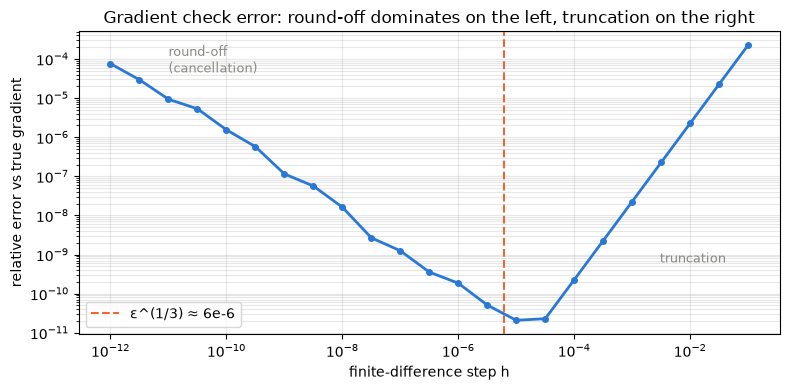

best h on this problem: 1e-05


In [14]:
steps = np.logspace(-12, -1, 23)
g_true = grad_correct(w0)
errors = [relative_error(g_true, numerical_grad(loss, w0, h)) for h in steps]
best_h = steps[int(np.argmin(errors))]

fig, ax = plt.subplots(figsize=(8, 4))
ax.loglog(steps, errors, marker="o", ms=4, lw=2, color=COLORS["blue"])
ax.axvline(np.finfo(float).eps ** (1 / 3), color=COLORS["orange"], ls="--", label="ε^(1/3) ≈ 6e-6")
ax.set_xlabel("finite-difference step h"); ax.set_ylabel("relative error vs true gradient")
ax.set_title("Gradient check error: round-off dominates on the left, truncation on the right")
ax.text(1e-11, max(errors) / 5, "round-off\n(cancellation)", fontsize=9, color=COLORS["grey"])
ax.text(3e-3, min(errors) * 30, "truncation", fontsize=9, color=COLORS["grey"])
ax.legend(); ax.grid(alpha=0.3, which="both"); plt.tight_layout(); plt.show()
print(f"best h on this problem: {best_h:.0e}")

**Rule:** whenever you hand-write a gradient (custom loss, custom layer, a from-scratch implementation like those in this course), add a gradient-check unit test with $h\approx10^{-5}$ and a relative-error threshold. Run it on a small random problem in float64, never float32.

---
## 10. Automated tests for the numerical helpers

Numerical code needs tests that use **tolerances** (`np.allclose`) and **adversarial inputs** (huge, tiny, nearly equal values), not only "nice" numbers.

In [15]:
def test_softmax_is_stable_and_shift_invariant():
    z = np.array([1000.0, 999.0, -1000.0])
    p = softmax_stable(z)
    assert np.all(np.isfinite(p)) and np.isclose(p.sum(), 1.0)
    assert np.allclose(softmax_stable(z - 500), p)                   # softmax(z + c) == softmax(z)


def test_log_sum_exp_matches_scipy():
    for z in (rng.normal(size=10), np.array([1e4, 1e4]), np.array([-1e4, -1e4 + 1])):
        assert np.isclose(log_sum_exp(z), logsumexp(z))


def test_variance_is_stable_with_large_offset():
    assert np.isclose(var_two_pass(readings), np.var(readings), rtol=1e-6)
    assert np.isclose(var_welford(readings[:20_000]), np.var(readings[:20_000]), rtol=1e-6)


def test_lstsq_fits_to_noise_level():
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    assert np.sqrt(np.mean((X @ beta - y) ** 2)) < 0.02


def test_gradient_check_passes_and_catches_bug():
    w = rng.normal(size=n_feat)
    assert relative_error(grad_correct(w), numerical_grad(loss, w)) < 1e-6
    assert relative_error(grad_buggy(w), numerical_grad(loss, w)) > 1e-4


def test_vectorised_distances_match_loops():
    assert np.allclose(distances_loops(customers[:20], stores[:20]), distances_matmul(customers[:20], stores[:20]), atol=1e-6)


for test in [test_softmax_is_stable_and_shift_invariant, test_log_sum_exp_matches_scipy,
             test_variance_is_stable_with_large_offset, test_lstsq_fits_to_noise_level,
             test_gradient_check_passes_and_catches_bug, test_vectorised_distances_match_loops]:
    test()
    print(f"PASSED  {test.__name__}")

PASSED  test_softmax_is_stable_and_shift_invariant
PASSED  test_log_sum_exp_matches_scipy
PASSED  test_variance_is_stable_with_large_offset
PASSED  test_lstsq_fits_to_noise_level
PASSED  test_gradient_check_passes_and_catches_bug
PASSED  test_vectorised_distances_match_loops


---
## 11. The math bug checklist, summary, exercises and resources

### Math bug checklist (use it in code reviews)

| Symptom | Likely cause | Fix |
|---|---|---|
| `a == b` fails for "equal" floats | rounding | `np.isclose` / `math.isclose` with explicit tolerances |
| Totals off by cents or more | float32 running sums, money in floats | float64 accumulators, `np.sum`/`math.fsum`, integer cents or `Decimal` |
| Negative variance, `sqrt` of negative | catastrophic cancellation ($E[x^2]-E[x]^2$) | two-pass / Welford, center data first |
| `log(1+x)` or `exp(x)-1` equals 0 for small x | cancellation | `np.log1p`, `np.expm1` |
| `NaN`/`inf` in probabilities or loss | `exp` overflow, `log(0)` | subtract the max, log-sum-exp, `log_softmax`, losses on **logits** |
| Product of probabilities is exactly 0 | underflow | sum of log-probabilities |
| Coefficients jump after tiny data changes | ill-conditioned $X^\top X$ | `lstsq`/QR instead of `inv`, scale features, regularise, check `np.linalg.cond` |
| Training slow or converges to a worse model | wrong hand-written gradient | gradient check with central differences, $h\approx10^{-5}$ |
| Pipeline takes hours | Python loops over rows | vectorise (broadcasting, matmul), chunk large arrays |
| "KPI went up!" | sampling noise | CI (normal or bootstrap), sample size, check coverage for skewed data |

### Summary

| Section | Math from this folder | Where it bites in industry |
|---|---|---|
| Floating point & summation | number representation | dashboards, finance, mixed-precision training |
| Cancellation & Welford | variance (`04_statistics`) | monitoring, streaming statistics, feature scaling |
| Log-sum-exp | softmax, cross-entropy (`05_information_theory`) | every classifier and language model |
| Condition numbers | inverse, SVD (`01_linear_algebra`) | regression, recommender systems, Kalman filters |
| Vectorisation | matrix multiplication (`01_linear_algebra`) | feature pipelines, nearest-neighbour search |
| Bootstrap & coverage | CIs (`04_statistics`, `03_probability`) | KPI reports, A/B tests |
| Gradient checking | derivatives, chain rule (`02_calculus`, `06_optimization`) | custom losses and layers |

### Practice exercises
1. Repeat the summation experiment with `float16`. At what running total does adding $1 stop changing the sum?
2. Implement `sigmoid` that never overflows for large negative inputs (hint: use different formulas for $z\ge0$ and $z<0$) and test it on `[-1000, 0, 1000]`.
3. In Section 6, increase the polynomial degree from 7 to 10. Plot $\kappa(X)$ against the degree for raw and standardised features.
4. Write a chunked version of `distances_matmul` that never holds more than 10 million distances in memory at once.
5. Use the gradient check on your own from-scratch implementation from `06_optimization.ipynb` (e.g. Adam on a quadratic).

### Resources (checked)
- David Goldberg, *What Every Computer Scientist Should Know About Floating-Point Arithmetic*: https://docs.oracle.com/cd/E19957-01/806-3568/ncg_goldberg.html
- Python docs, *Floating-Point Arithmetic: Issues and Limitations*: https://docs.python.org/3/tutorial/floatingpoint.html
- NumPy `sum` (pairwise summation note): https://numpy.org/doc/stable/reference/generated/numpy.sum.html
- Welford's online algorithm (Wikipedia, *Algorithms for calculating variance*): https://en.wikipedia.org/wiki/Algorithms_for_calculating_variance
- SciPy `logsumexp`: https://docs.scipy.org/doc/scipy/reference/generated/scipy.special.logsumexp.html
- PyTorch `CrossEntropyLoss` (takes logits): https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html
- John D. Cook, *Don't invert that matrix*: https://www.johndcook.com/blog/2010/01/19/dont-invert-that-matrix/
- NumPy `linalg.lstsq` and `linalg.cond`: https://numpy.org/doc/stable/reference/generated/numpy.linalg.lstsq.html
- Stanford CS231n notes, *Gradient checks*: https://cs231n.github.io/neural-networks-3/#gradcheck
- PyTorch `torch.autograd.gradcheck`: https://pytorch.org/docs/stable/generated/torch.autograd.gradcheck.gradcheck.html
- Deep Learning Book, Chapter 4 *Numerical Computation*: https://www.deeplearningbook.org/contents/numerical.html

### Related notebooks in this repo
- `01_linear_algebra.ipynb`: inverse, SVD, condition of matrices
- `02_calculus.ipynb`: finite differences and automatic differentiation
- `04_statistics.ipynb`: bootstrap, confidence intervals, multiple testing
- `05_information_theory.ipynb`: softmax, cross-entropy, KL divergence
- `06_optimization.ipynb`: gradient descent and the optimisers that consume your gradients
- `../02_Data_Analysis/02_numpy.ipynb`: vectorisation and broadcasting basics